# HW3 --- Unconstrained Optimization

**Naim El Rouwadi — Student ID: 261031398**

## Questions 4, 5 and 6

Each part has one code cell containing its calculations, plots, and results before the next part begins.
Written explanations and derivations are in the separate `overleaf/main.tex` project.

## Setup: imports and output folders

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import fsolve, minimize
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd()
if not (ROOT / "data" / "Q.txt").is_file() and (ROOT / "HW3" / "data" / "Q.txt").is_file():
    ROOT = ROOT / "HW3"
OUT = ROOT / "results"
FIG = ROOT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
np.set_printoptions(precision=10, suppress=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda value: f"{value:.10g}")

def vector_text(values, precision=10):
    return "(" + ", ".join(f"{v:.{precision}g}" for v in values) + ")"

plt.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .15})
summary = {"versions": {"numpy": np.__version__, "scipy": scipy.__version__}}

## Question 4 --- Stationary points and Hessian definiteness

$$f(x_1,x_2)=\frac{x_1^3}{3}+x_1x_2+\frac{x_2^2}{2}+2x_2-\frac{2}{3}.$$

Course sources: [L05 SOSC demonstration, Section 2](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L05/L05_SOSC_demonstration.ipynb)
and [L06 stabilization and scaling, Section 2](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L06/L06_stabilization_and_scaling.ipynb).

### 4(a) - Stationary points from five initial guesses

In [2]:
def numerical_gradient(func, x, h=1e-6):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    g = np.zeros_like(x)
    for i in range(len(x)):
        step = np.zeros_like(x)
        step[i] = h
        g[i] = (func(x + step) - func(x - step)) / (2 * h)
    return g

def numerical_hessian(func, x, h=1e-4):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    n = len(x)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            si = np.zeros(n); si[i] = h
            sj = np.zeros(n); sj[j] = h
            H[i, j] = (func(x + si + sj) - func(x + si - sj) - func(x - si + sj) + func(x - si - sj)) / (4 * h**2)
    return H

def classify_stationary_point(func, x_star, tol=1e-6):
    H = numerical_hessian(func, x_star)
    eigs = np.linalg.eigvalsh(H)
    if np.all(eigs > tol):
        label = "local minimizer"
    elif np.all(eigs < -tol):
        label = "local maximizer"
    elif np.any(eigs > tol) and np.any(eigs < -tol):
        label = "saddle point"
    else:
        label = "inconclusive (Hessian only semi-definite)"
    return label, eigs, H

def find_stationary_points(func, starting_points, grad_tol=1e-6, dedupe_tol=1e-3):
    found = []
    for x0 in starting_points:
        x0 = np.atleast_1d(np.asarray(x0, dtype=float))
        x_star, info, ier, msg = fsolve(lambda x: numerical_gradient(func, x), x0, full_output=True)
        if ier != 1 or np.max(np.abs(numerical_gradient(func, x_star))) > grad_tol:
            continue
        if not any(np.linalg.norm(x_star - existing) < dedupe_tol for existing in found):
            found.append(x_star)
    return found

def f4(x):
    a, b = x
    return a**3 / 3 + a*b + b**2 / 2 + 2*b - 2/3

def g4(x):
    a, b = x
    return np.array([a*a + b, a + b + 2])

def H4(x):
    return np.array([[2*x[0], 1.0], [1.0, 1.0]])

q4_starts = np.array([[0, 0], [-2, -2], [-1, 0], [1, -3], [3, -5]], dtype=float)
q4_rows = []
for start in q4_starts:
    roots = find_stationary_points(f4, [start])
    if len(roots) != 1:
        raise RuntimeError(f"The course finder did not converge from {start}.")
    point = roots[0]
    label, numerical_eigs, _ = classify_stationary_point(f4, point)
    exact_eigs = np.linalg.eigvalsh(H4(point))
    q4_rows.append({"start": start.tolist(), "point": point.tolist(),
                    "f": float(f4(point)), "grad_norm": float(np.linalg.norm(g4(point))),
                    "eigenvalues": exact_eigs.tolist(), "nature": label})
    assert np.allclose(numerical_eigs, exact_eigs, atol=2e-6)
summary["q4"] = q4_rows

# 4(a) - Results: initial guesses and stationary points

q4_stationary_table = pd.DataFrame([
    {"Start": i, "Initial guess": vector_text(row["start"]),
     "x1": row["point"][0], "x2": row["point"][1],
     "f(x)": row["f"], "||grad f||2": row["grad_norm"]}
    for i, row in enumerate(q4_rows, 1)
]).set_index("Start")
print("Question 4(a) - Stationary points from each initial guess")
print(q4_stationary_table.to_string(float_format=lambda value: f"{value:.6g}"))

Question 4(a) - Stationary points from each initial guess
      Initial guess  x1  x2  f(x)  ||grad f||2
Start                                         
1            (0, 0)  -1  -1  -1.5  7.80964e-11
2          (-2, -2)  -1  -1  -1.5  1.16929e-11
3           (-1, 0)  -1  -1  -1.5  7.01368e-11
4           (1, -3)   2  -4    -6   5.0631e-10
5           (3, -5)   2  -4    -6  4.27131e-10


### 4(b) - Hessian classification and Newton's method

In [3]:
# Verify the specific plain-Newton example with analytical derivatives.
x = np.zeros(2)
q4_newton_path = [x.copy()]
for _ in range(50):
    if np.linalg.norm(g4(x)) <= 1e-10:
        break
    x = x + np.linalg.solve(H4(x), -g4(x))
    q4_newton_path.append(x.copy())
assert np.allclose(x, [-1, -1], atol=1e-8)

# 4(b) - Results: Hessian eigenvalues and classification

q4_unique = {tuple(np.round(row["point"], 6)): row for row in q4_rows}
q4_classification_table = pd.DataFrame([
    {"Point": vector_text(point, 6), "lambda 1": row["eigenvalues"][0],
     "lambda 2": row["eigenvalues"][1],
     "Hessian": "Positive definite" if min(row["eigenvalues"]) > 0 else "Indefinite",
     "Nature": row["nature"]}
    for point, row in q4_unique.items()
]).set_index("Point")
print("Question 4(b) - Hessian eigenvalues and classification")
print(q4_classification_table.to_string(float_format=lambda value: f"{value:.6g}"))

# 4(b) - Plain Newton result

q4_newton_final = q4_newton_path[-1]
q4_newton_table = pd.DataFrame([{
    "Initial guess": vector_text(q4_newton_path[0]),
    "Final point": vector_text(q4_newton_final),
    "f(x)": f4(q4_newton_final), "||grad f||2": np.linalg.norm(g4(q4_newton_final)),
    "Iterations k": len(q4_newton_path)-1,
    "Nature": classify_stationary_point(f4, q4_newton_final)[0]
}]).set_index("Initial guess")
print("\nQuestion 4(b) - Plain Newton result")
print(q4_newton_table.to_string(float_format=lambda value: f"{value:.6g}"))

Question 4(b) - Hessian eigenvalues and classification
          lambda 1  lambda 2            Hessian           Nature
Point                                                           
(-1, -1)  -2.30278   1.30278         Indefinite     saddle point
(2, -4)   0.697224   4.30278  Positive definite  local minimizer

Question 4(b) - Plain Newton result
              Final point  f(x)  ||grad f||2  Iterations k        Nature
Initial guess                                                           
(0, 0)           (-1, -1)  -1.5            0             6  saddle point


## Question 5 --- Rosenbrock function: gradient method vs. Newton's method

$$f(x_1,x_2)=(1-x_1)^2+100(x_2-x_1^2)^2.$$

Course sources: [L06 gradient descent and line search, Section 4](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L06/L06_gradient_descent_and_line_search.ipynb)
and [L06 Newton and quasi-Newton, Section 1](https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L06/L06_newton_and_quasi_newton.ipynb).

Initial guesses: $(-1.2,1)$, $(-1,-1)$, $(0,0)$, $(1,0)$, $(1,1.2)$.
Stopping tolerance: $10^{-3}$; maximum iterations: $5000$.

### 5(a) - Gradient and Newton methods from five initial guesses

In [4]:
def rosen(x):
    a, b = x
    return (1-a)**2 + 100*(b-a*a)**2

def rosen_grad(x):
    a, b = x
    return np.array([2*(a-1)-400*a*(b-a*a), 200*(b-a*a)])

def rosen_hess(x):
    a, b = x
    return np.array([[1200*a*a-400*b+2, -400*a], [-400*a, 200.]])

def armijo_backtrack(func, grad_func, x, d, alpha0=1.0, eps=0.1, beta=0.85, max_iter=60):
    phi0 = func(x)
    dphi0 = grad_func(x) @ d
    alpha = alpha0
    for _ in range(max_iter):
        if func(x + alpha*d) <= phi0 + eps*alpha*dphi0:
            return alpha
        alpha *= beta
    return alpha

def exact_line_search_gd_general(func, grad_func, hess_func, x0, n_iter=5000, tol=1e-3):
    # Adapted from L06 exact_line_search_gd: evaluate g and H at each iterate,
    # use the prescribed curvature step, and apply the course Armijo fallback.
    x = np.asarray(x0, dtype=float).copy()
    traj = [x.copy()]
    alphas, fallback_iterations = [], []
    for k in range(n_iter):
        g = grad_func(x)
        if np.linalg.norm(g) <= tol:
            break
        H = hess_func(x)
        curvature = g @ H @ g
        if curvature > 0:
            alpha = (g @ g) / curvature
        else:
            alpha = armijo_backtrack(func, grad_func, x, -g,
                                      alpha0=1., eps=.1, beta=.85)
            # The course helper returns its last trial at its limit: check acceptance.
            if func(x-alpha*g) > func(x)-.1*alpha*(g@g):
                raise RuntimeError("Armijo fallback did not accept a step.")
            fallback_iterations.append(k)
        x = x - alpha*g
        if not np.all(np.isfinite(x)):
            raise FloatingPointError("Nonfinite gradient iterate.")
        traj.append(x.copy())
        alphas.append(alpha)
    return np.array(traj), np.array(alphas), fallback_iterations

# L06 newton_method; only the stopping comparison changes from < to <=.
def newton_method(func, x0, n_iter=20, tol=1e-8):
    x = np.array(x0, dtype=float)
    traj = [x.copy()]
    for k in range(n_iter):
        g = numerical_gradient(func, x)
        if np.linalg.norm(g) <= tol:
            break
        H = numerical_hessian(func, x)
        d = np.linalg.solve(H, -g)
        x = x + d
        traj.append(x.copy())
    return np.array(traj)

q5_starts = np.array([[-1.2,1], [-1,-1], [0,0], [1,0], [1,1.2]], dtype=float)
TOL5, MAX5 = 1e-3, 5000
q5_rows, q5_paths = [], {}
for start_id, start in enumerate(q5_starts, 1):
    gd, alphas, fallback = exact_line_search_gd_general(
        rosen, rosen_grad, rosen_hess, start, MAX5, TOL5)
    newton = newton_method(rosen, start, n_iter=MAX5, tol=TOL5)
    for method, trajectory in [("Gradient", gd), ("Newton", newton)]:
        x = trajectory[-1]
        analytic_norm = float(np.linalg.norm(rosen_grad(x)))
        stopping_norm = (analytic_norm if method == "Gradient" else
                         float(np.linalg.norm(numerical_gradient(rosen, x))))
        q5_rows.append({"start_id": start_id, "method": method, "start": start.tolist(),
                       "x1": float(x[0]), "x2": float(x[1]), "f": float(rosen(x)),
                       "grad_norm": stopping_norm, "analytical_grad_norm": analytic_norm,
                       "iterations": len(trajectory)-1,
                       "status": "tolerance" if stopping_norm <= TOL5 else "iteration limit",
                       "fallback_iterations": fallback if method == "Gradient" else []})
        q5_paths[(start_id, method)] = trajectory
        np.savetxt(OUT / f"q5_start{start_id}_{method.lower()}_iterates.csv",
                   np.column_stack([np.arange(len(trajectory)), trajectory]),
                   delimiter=",", header="k,x1,x2", comments="", fmt="%.17g")
summary["q5"] = q5_rows

# 5(a) - Results: final solutions, termination criteria, and iterations

q5_results_table = pd.DataFrame([
    {"Start": row["start_id"], "Method": row["method"],
     "Initial guess": vector_text(row["start"]), "x1": row["x1"], "x2": row["x2"],
     "f(x)": row["f"], "||grad f||2": row["grad_norm"],
     "Iterations k": row["iterations"]}
    for row in q5_rows
]).set_index(["Start", "Method"])
print("Question 5(a) - Final solutions, termination criteria, and iterations")
print(q5_results_table.to_string(float_format=lambda value: f"{value:.8g}"))

Question 5(a) - Final solutions, termination criteria, and iterations
               Initial guess         x1         x2          f(x)   ||grad f||2  Iterations k
Start Method                                                                                
1     Gradient     (-1.2, 1) 0.99890994  0.9978163 1.1905003e-06 0.00099206692           611
      Newton       (-1.2, 1) 0.99999526 0.99999052 2.2448695e-11 9.4763562e-06             5
2     Gradient      (-1, -1)  0.9989078 0.99781283 1.1944746e-06 0.00099431872          1816
      Newton        (-1, -1)          1          1  1.348871e-17 7.7600231e-09             5
3     Gradient        (0, 0) 0.99901785 0.99803168 9.6710333e-07  0.0009981398          3355
      Newton          (0, 0) 0.99999602 0.99999204 1.5851212e-11 7.5734611e-06             2
4     Gradient        (1, 0) 0.99901785 0.99803168 9.6710333e-07  0.0009981398          3354
      Newton          (1, 0)          1          1 5.8786183e-17  3.301378e-07             1


### 5(b) - Contour plots of all iterates and convergence

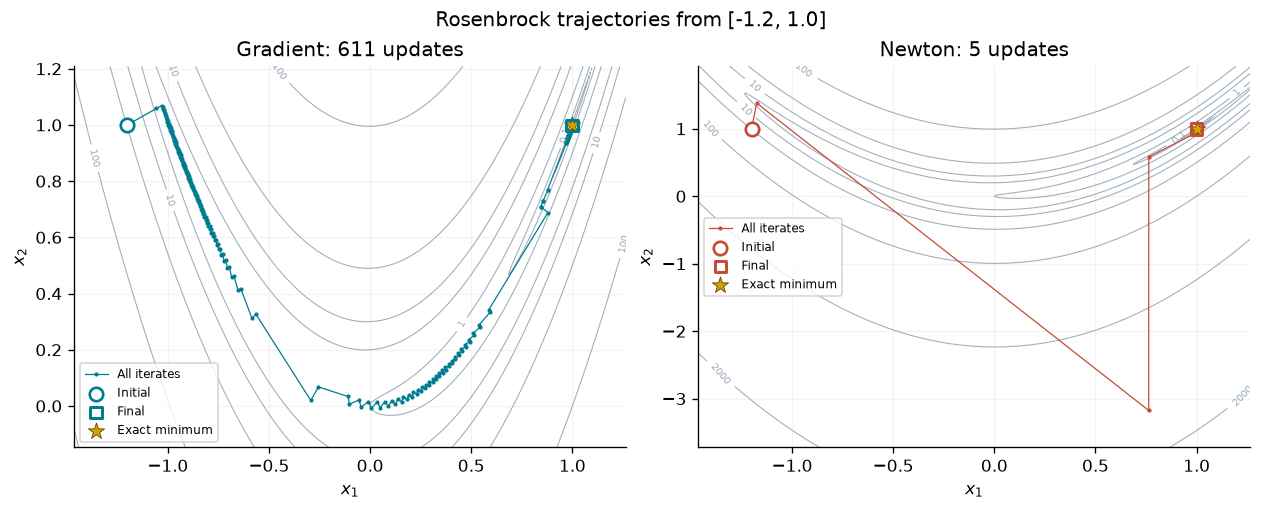

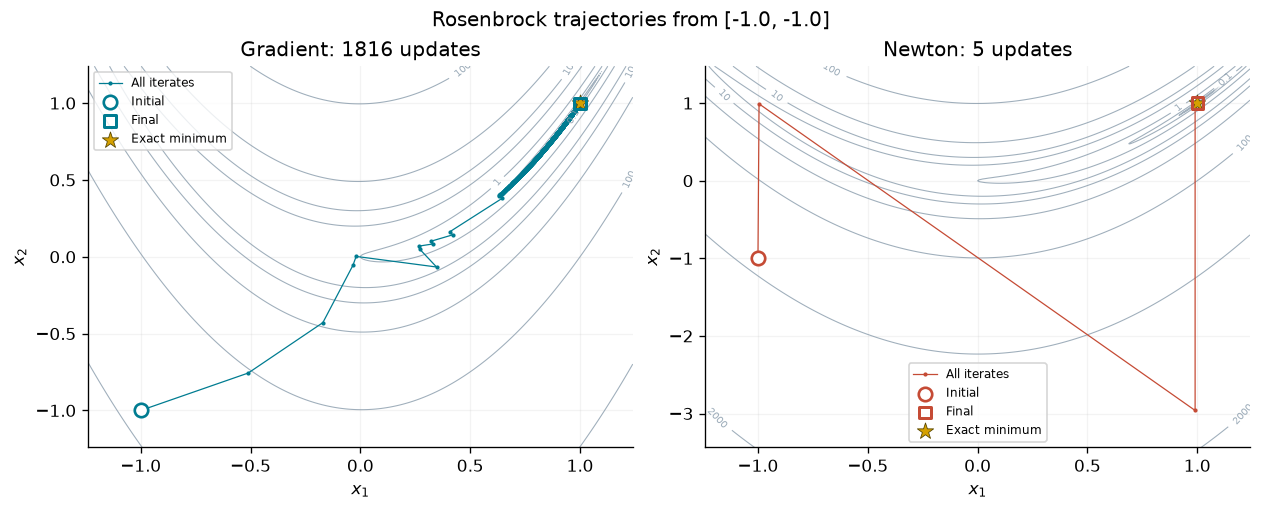

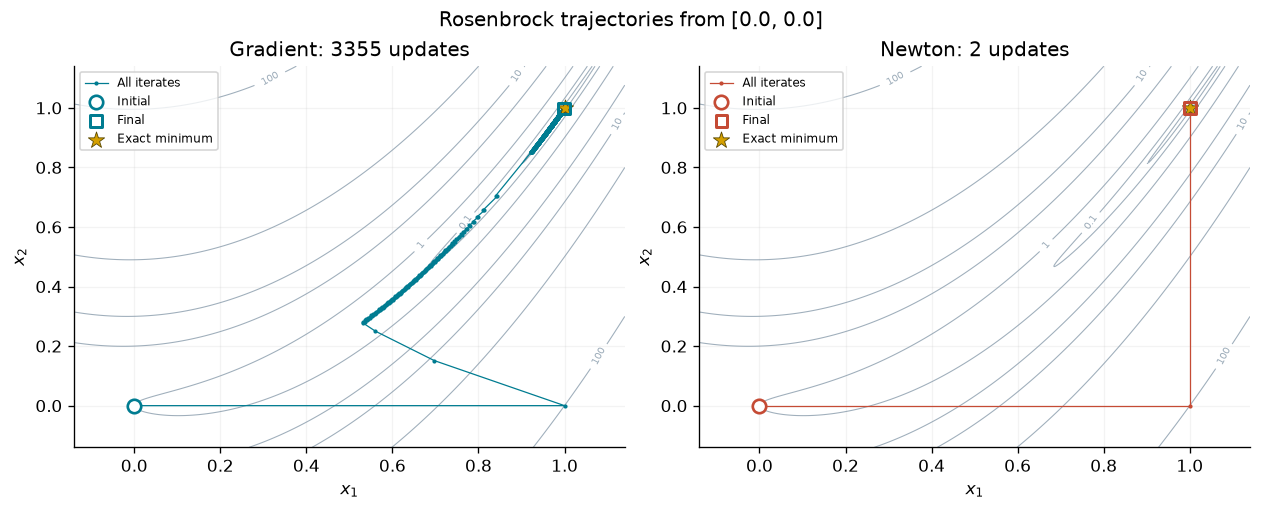

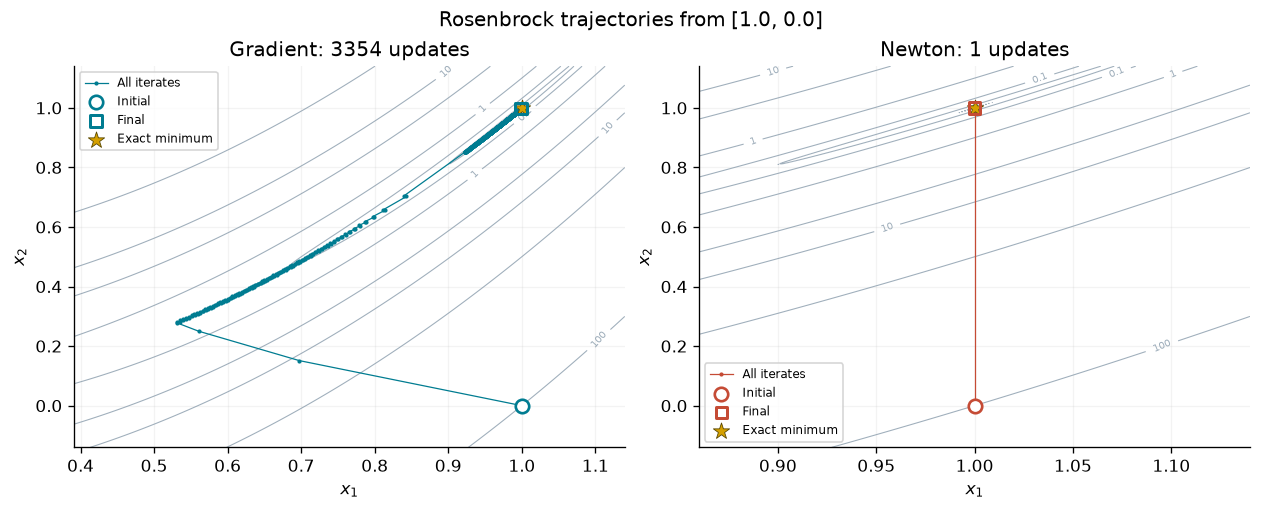

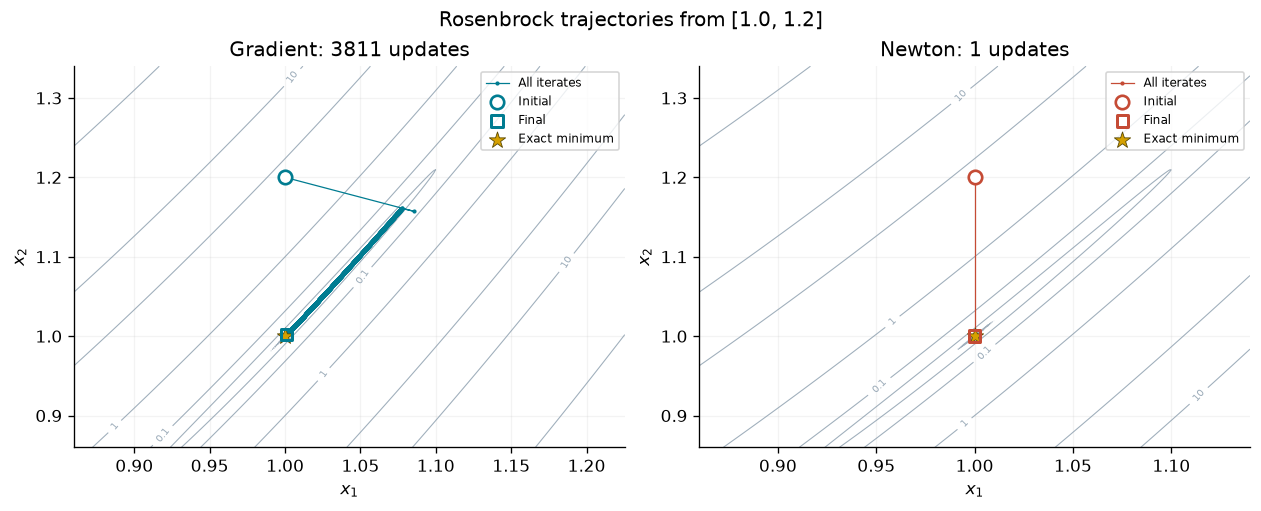

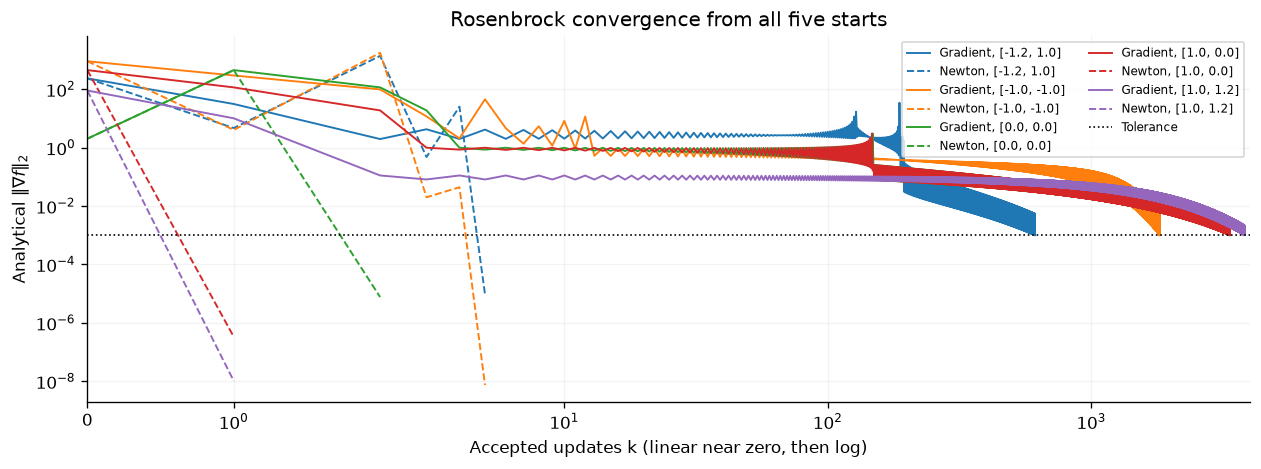

In [5]:
levels = np.array([1e-6, 1e-4, .01, .1, 1, 5, 10, 25, 100, 500, 2000, 10000])
for sid, start in enumerate(q5_starts, 1):
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.15), constrained_layout=True)
    for ax, method, color in zip(axes, ["Gradient", "Newton"], ["#007c91", "#c54b35"]):
        tr = q5_paths[(sid, method)]
        allpoints = np.vstack([tr, [1,1]])
        lo, hi = allpoints.min(axis=0), allpoints.max(axis=0)
        padding = np.maximum(.12*(hi-lo), .14)
        lo -= padding; hi += padding
        xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 420), np.linspace(lo[1], hi[1], 420))
        zz = (1-xx)**2 + 100*(yy-xx**2)**2
        contours = ax.contour(xx, yy, zz, levels=levels, colors="#889bab",
                              linewidths=.65, alpha=.8)
        ax.clabel(contours, levels=[.1, 1, 10, 100, 2000], inline=True,
                  fontsize=6, fmt="%g")
        ax.plot(tr[:,0], tr[:,1], "o-", color=color, lw=.75, ms=1.5, label="All iterates")
        ax.scatter(*tr[0], marker="o", s=65, facecolor="white", edgecolor=color, lw=1.6,
                   zorder=5, label="Initial")
        ax.scatter(*tr[-1], marker="s", s=48, facecolor="none", edgecolor=color,
                   lw=1.8, zorder=6, label="Final")
        ax.scatter(1, 1, marker="*", s=105, color="#d5a000", edgecolor="#594800",
                   lw=.5, zorder=4, label="Exact minimum")
        ax.set(xlim=(lo[0],hi[0]), ylim=(lo[1],hi[1]), xlabel="$x_1$", ylabel="$x_2$",
               title=f"{method}: {len(tr)-1} updates")
        ax.legend(fontsize=7, loc="best")
    fig.suptitle(f"Rosenbrock trajectories from {start.tolist()}", fontsize=12)
    fig.savefig(FIG / f"q5_paths_{sid}.png", dpi=210)
    plt.show()

fig, ax = plt.subplots(figsize=(10.4,3.8), constrained_layout=True)
for sid, start in enumerate(q5_starts, 1):
    color = plt.get_cmap("tab10")(sid-1)
    for method, style in [("Gradient","-"), ("Newton","--")]:
        tr = q5_paths[(sid,method)]
        residuals = [np.linalg.norm(rosen_grad(x)) for x in tr]
        ax.semilogy(np.arange(len(tr)), residuals, style, color=color, lw=1.15,
                    label=f"{method}, {start.tolist()}")
ax.axhline(TOL5, color="black", ls=":", lw=1, label="Tolerance")
ax.set(xscale="symlog", xlabel="Accepted updates k (linear near zero, then log)",
       ylabel=r"Analytical $\|\nabla f\|_2$", title="Rosenbrock convergence from all five starts")
ax.set_xlim(0, 4000)
ax.legend(fontsize=7, ncol=2, loc="upper right")
fig.savefig(FIG / "q5_convergence.png", dpi=210)
plt.show()

## Question 6 --- Own gradient descent with Armijo line search

$$f(x)=x^TQx+b^Tx+c.$$

Data: [professor's Q6 folder](https://github.com/Ahmed-Bayoumy/MECH559/tree/DEV/Assignments/HW3/Q6).
Part (a) uses an independently implemented gradient descent and Armijo search.

Settings: $x_0=0$, $\epsilon_{tol}=10^{-6}$, $k_{max}=5000$,
$\alpha_0=1$, $\epsilon=0.15$, $\beta=0.85$.

### 6(a) - Implementation and numerical solution

In [6]:
# 6(a)(i)-(iv) - Termination point, objective value, gradient norm, and iteration count

Q = np.loadtxt(ROOT / "data" / "Q.txt")
b = np.loadtxt(ROOT / "data" / "b.txt")
c = float(np.loadtxt(ROOT / "data" / "c.txt"))
assert Q.shape == (len(b),len(b))
assert np.allclose(Q, Q.T, rtol=0, atol=1e-14)
eigenvalues_Q = np.linalg.eigvalsh(Q)
assert eigenvalues_Q.min() > 0

def f6(x):
    return float(x @ Q @ x + b @ x + c)

def g6(x):
    return 2*Q @ x + b

def own_gradient_armijo(func, grad, x0, tol=1e-6, max_iter=5000,
                        alpha0=1., epsilon=.15, beta=.85):
    if not (alpha0 > .5 and .1 <= epsilon <= .2 and .8 <= beta <= .9):
        raise ValueError("The line-search parameters must satisfy Q6's ranges.")
    x = np.asarray(x0, dtype=float).copy()
    trajectory, log = [x.copy()], []
    for k in range(max_iter):
        gradient = grad(x)
        norm = np.linalg.norm(gradient)
        if norm <= tol:
            break
        direction = -gradient
        slope = float(gradient @ direction)
        value = func(x)
        alpha = alpha0
        reductions = 0
        while True:
            candidate = x + alpha*direction
            candidate_value = func(candidate)
            bound = value + epsilon*alpha*slope
            if np.isfinite(candidate_value) and candidate_value <= bound:
                break
            alpha *= beta
            reductions += 1
            if reductions >= 1000 or alpha == 0:
                raise RuntimeError("Armijo search failed to find an acceptable step.")
        log.append({"k": k, "alpha": float(alpha), "reductions": reductions,
                    "f_before": value, "f_after": candidate_value,
                    "armijo_bound": bound, "grad_norm_before": float(norm)})
        x = candidate
        trajectory.append(x.copy())
    residual = float(np.linalg.norm(grad(x)))
    return {"x": x, "fun": func(x), "grad_norm": residual,
            "nit": len(trajectory)-1, "success": residual <= tol,
            "trajectory": np.array(trajectory), "log": log}

TOL6, MAX6 = 1e-6, 5000
x06 = np.zeros(len(b))
own = own_gradient_armijo(f6, g6, x06, tol=TOL6, max_iter=MAX6)
assert own["success"]

# 6(a)(i)-(iv) - Results: own Armijo gradient descent

q6_own_table = pd.DataFrame([
    {"Part": "6(a)(i)", "Result": "Termination point x_k", "Value": vector_text(own["x"])},
    {"Part": "6(a)(ii)", "Result": "Objective f(x_k)", "Value": f"{own['fun']:.14g}"},
    {"Part": "6(a)(iii)", "Result": "Tolerance reached: ||grad f||2", "Value": f"{own['grad_norm']:.10g}"},
    {"Part": "6(a)(iv)", "Result": "Iterations k", "Value": str(own["nit"])}
]).set_index("Part")
print("Question 6(a)(i)-(iv) - Own Armijo gradient descent results")
print(q6_own_table.to_string())

Question 6(a)(i)-(iv) - Own Armijo gradient descent results
                                   Result                                                                    Value
Part                                                                                                              
6(a)(i)             Termination point x_k  (-0.3969396723, 0.62551752, -0.2359955067, -0.5649794558, 0.3566708457)
6(a)(ii)                 Objective f(x_k)                                                        0.058385676974864
6(a)(iii)  Tolerance reached: ||grad f||2                                                           8.85155944e-07
6(a)(iv)                     Iterations k                                                                      473


### 6(b) - FONC solution

In [7]:
xstar = np.linalg.solve(2*Q, -b)
fstar = f6(xstar)
fstar_formula = c - .25*b @ np.linalg.solve(Q,b)

# 6(b) - Results: FONC solution and objective value

q6_fonc_table = pd.DataFrame([
    {"Result": "x*", "Value": vector_text(xstar)},
    {"Result": "f(x*)", "Value": f"{fstar:.14g}"}
]).set_index("Result")
print("Question 6(b) - FONC solution and objective value")
print(q6_fonc_table.to_string())

Question 6(b) - FONC solution and objective value
                                                                           Value
Result                                                                          
x*      (-0.3969408448, 0.6255180839, -0.235994814, -0.5649809594, 0.3566716344)
f(x*)                                                          0.058385676974331


### 6(c) - Comparison with SciPy BFGS

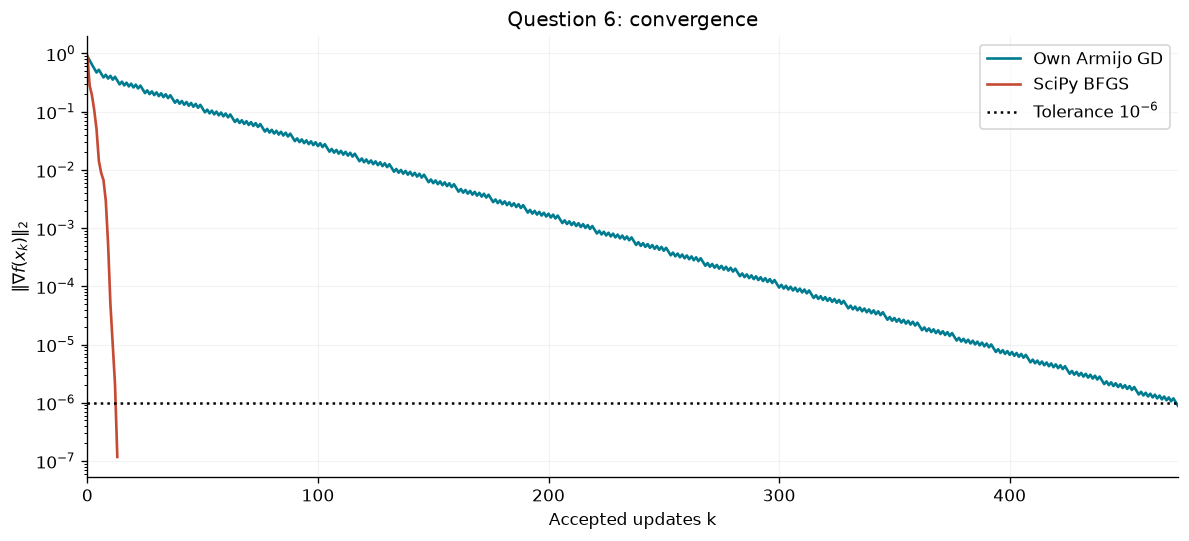

Question 6(c) - Termination-point comparison
           Own Armijo GD          FONC    SciPy BFGS
Component                                           
x1         -0.3969396723 -0.3969408448 -0.3969407448
x2            0.62551752  0.6255180839  0.6255182757
x3         -0.2359955067  -0.235994814 -0.2359951368
x4         -0.5649794558 -0.5649809594 -0.5649807788
x5          0.3566708457  0.3566716344  0.3566716686

Question 6(c) - Objective, gradient norm, and iteration comparison
                           f(x)         ||grad f||2  Iterations k           ||x-x*||2
Method                                                                               
Own Armijo GD 0.058385676974864 8.8515594402716e-07           473  2.248427024129e-06
FONC          0.058385676974331  3.002224531865e-16  Direct solve                   0
SciPy BFGS    0.058385676974354 1.1722539887191e-07            13 4.2975468131114e-07


In [8]:
q6_solver_path = [x06.copy()]
solver = minimize(f6, x06, jac=g6, method="BFGS",
                  callback=lambda xk: q6_solver_path.append(xk.copy()),
                  options={"gtol": TOL6, "norm": 2, "maxiter": MAX6})
q6_rows = []
for method, x, nit in [("Own Armijo GD", own["x"], own["nit"]),
                        ("FONC", xstar, None), ("SciPy BFGS", solver.x, int(solver.nit))]:
    q6_rows.append({"method": method, "x": x.tolist(), "f": f6(x),
                   "grad_norm": float(np.linalg.norm(g6(x))), "iterations": nit,
                   "distance_to_exact": float(np.linalg.norm(x-xstar)),
                   "objective_gap": f6(x)-fstar})
summary["q6"] = {"settings": {"x0": x06.tolist(), "tol": TOL6, "max_iter": MAX6,
                   "alpha0": 1., "epsilon": .15, "beta": .85},
                 "eigenvalues_Q": eigenvalues_Q.tolist(), "condition_Q": float(np.linalg.cond(Q)),
                 "rows": q6_rows, "solver_success": bool(solver.success),
                 "solver_message": str(solver.message), "solver_nfev": int(solver.nfev),
                 "solver_njev": int(solver.njev)}
pd.DataFrame(own["log"]).to_csv(OUT / "q6_armijo_log.csv", index=False)
np.savetxt(OUT / "q6_own_iterates.csv", own["trajectory"], delimiter=",",
           header=",".join(f"x{i+1}" for i in range(len(b))), comments="", fmt="%.17g")

fig, ax = plt.subplots(figsize=(9.8, 4.4), constrained_layout=True)
for label, tr, color in [("Own Armijo GD", own["trajectory"], "#007c91"),
                          ("SciPy BFGS", np.array(q6_solver_path), "#c54b35")]:
    norms = np.array([np.linalg.norm(g6(point)) for point in tr])
    ax.semilogy(np.arange(len(tr)), norms, color=color, lw=1.6, label=label)
ax.axhline(TOL6, color="black", ls=":", label=r"Tolerance $10^{-6}$")
ax.set(xlabel="Accepted updates k", ylabel=r"$\|\nabla f(x_k)\|_2$",
       title="Question 6: convergence", xlim=(0, own["nit"]))
ax.legend()
fig.savefig(FIG / "q6_convergence.png", dpi=210)
plt.show()

# 6(c) - Results: termination-point comparison

q6_points_table = pd.DataFrame({row["method"]: row["x"] for row in q6_rows},
                             index=[f"x{i+1}" for i in range(len(b))])
q6_points_table.index.name = "Component"
print("Question 6(c) - Termination-point comparison")
print(q6_points_table.to_string(float_format=lambda value: f"{value:.10g}"))

# 6(c) - Objective, gradient norm, and iteration comparison

q6_comparison_table = pd.DataFrame([
    {"Method": row["method"], "f(x)": row["f"], "||grad f||2": row["grad_norm"],
     "Iterations k": row["iterations"] if row["iterations"] is not None else "Direct solve",
     "||x-x*||2": row["distance_to_exact"]}
    for row in q6_rows
]).set_index("Method")
print("\nQuestion 6(c) - Objective, gradient norm, and iteration comparison")
print(q6_comparison_table.to_string(float_format=lambda value: f"{value:.14g}"))
_ = (OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")